In [ ]:
!pip install -q ultralytics

In [ ]:
from pathlib import Path
DATASET_PATH=Path("/content/drive/MyDrive/Dataset_UAV123_10fps/UAV123_10fps")
print("Dataset exists",DATASET_PATH.exists())
print("contents",list(DATASET_PATH.iterdir())[:10])

Dataset exists True
contents [PosixPath('/content/drive/MyDrive/Dataset_UAV123_10fps/UAV123_10fps/configSeqs.m'), PosixPath('/content/drive/MyDrive/Dataset_UAV123_10fps/UAV123_10fps/ReadMe.txt'), PosixPath('/content/drive/MyDrive/Dataset_UAV123_10fps/UAV123_10fps/anno'), PosixPath('/content/drive/MyDrive/Dataset_UAV123_10fps/UAV123_10fps/data_seq')]


In [ ]:
import numpy as np
frames_dir=DATASET_PATH/"data_seq"
anno_dir=DATASET_PATH/"anno"

# Let's inspect the contents of the directories to see how the files are structured
print("Contents of 'data_seq':", list(frames_dir.iterdir())[:10])
print("Contents of 'anno':", list(anno_dir.iterdir())[:10])

sequence='person10'
frames=sorted(list((frames_dir/sequence).glob("*.jpg")))
print("Total frames found:", len(frames))

# Find files related to sequence in anno folder
anno_matches = list(anno_dir.rglob(f"*{sequence}*"))
print(f"Annotation files matching '{sequence}':", anno_matches)

frames = sorted(
    list((frames_dir / "UAV123_10fps" / sequence).glob("*.jpg"))
)

annotation_path = anno_dir / "UAV123_10fps" / f"{sequence}.txt"

boxes = np.loadtxt(
    annotation_path,
    delimiter=",",
    ndmin=2
)

print("Total frames:", len(frames))
print("Total annotations:", len(boxes))
print("Annotation shape:", boxes.shape)
print("First 5 annotations:")
print(boxes[:5])

Contents of 'data_seq': [PosixPath('/content/drive/MyDrive/Dataset_UAV123_10fps/UAV123_10fps/data_seq/UAV123_10fps')]
Contents of 'anno': [PosixPath('/content/drive/MyDrive/Dataset_UAV123_10fps/UAV123_10fps/anno/UAV123_10fps')]
Total frames found: 0
Annotation files matching 'person10': [PosixPath('/content/drive/MyDrive/Dataset_UAV123_10fps/UAV123_10fps/anno/UAV123_10fps/person10.txt'), PosixPath('/content/drive/MyDrive/Dataset_UAV123_10fps/UAV123_10fps/anno/UAV123_10fps/att/person10.txt')]
Total frames: 341
Total annotations: 341
Annotation shape: (341, 4)
First 5 annotations:
[[553. 555.  54. 102.]
 [525. 547.  59. 110.]
 [499. 536.  58. 119.]
 [472. 526.  58. 119.]
 [447. 518.  56. 104.]]


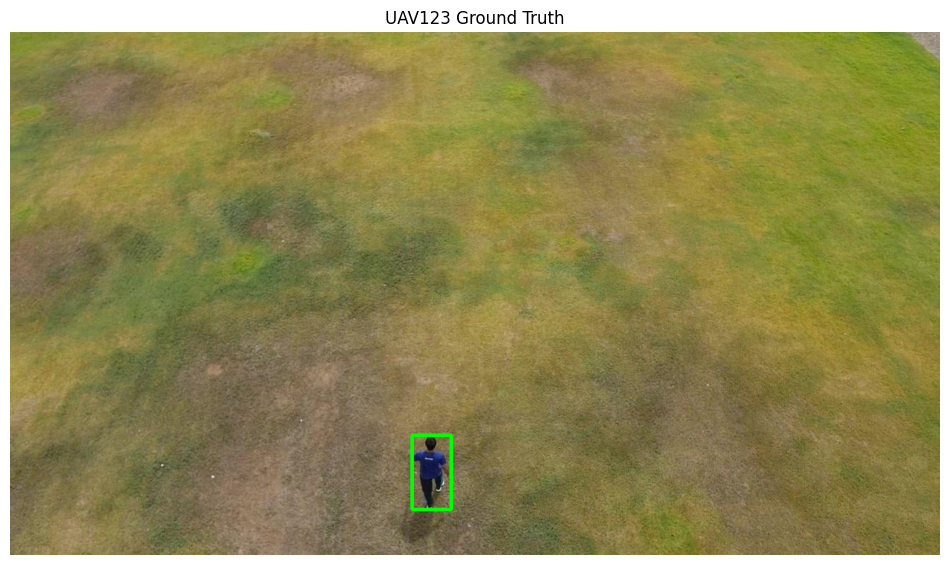

In [ ]:
import cv2
import matplotlib.pyplot as plt

frame=cv2.imread(str(frames[0]))
frame=cv2.cvtColor(frame,cv2.COLOR_BGR2RGB)
x,y,w,h=boxes[0].astype(int)

if w>0 and h>0:
  cv2.rectangle(frame,(x,y),(x+w,y+h),(0,255,0),3)

plt.figure(figsize=(12, 7))
plt.imshow(frame)
plt.axis("off")
plt.title("UAV123 Ground Truth")
plt.show()



In [ ]:
import cv2
import numpy as np
import random
import shutil
from pathlib import Path

OUTPUT = Path("/content/uav_yolo")

if OUTPUT.exists():
    shutil.rmtree(OUTPUT)

for split in ["train", "val"]:
    (OUTPUT / "images" / split).mkdir(
        parents=True, exist_ok=True
    )
    (OUTPUT / "labels" / split).mkdir(
        parents=True, exist_ok=True
    )

# Point search directories to the actual nested UAV123_10fps folders
actual_frames_dir = frames_dir / "UAV123_10fps"
actual_anno_dir = anno_dir / "UAV123_10fps"

sequences = sorted([
    p for p in actual_frames_dir.iterdir()
    if p.is_dir() and (actual_anno_dir / f"{p.name}.txt").exists()
])

random.Random(42).shuffle(sequences)

split_idx = int(len(sequences) * 0.8)
train_seqs = sequences[:split_idx]
val_seqs = sequences[split_idx:]

def convert_sequences(seq_list, split):
    count = 0

    for seq_dir in seq_list:
        frame_paths = sorted(
            p for p in seq_dir.iterdir()
            if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
        )

        boxes = np.loadtxt(
            actual_anno_dir / f"{seq_dir.name}.txt",
            delimiter=",",
            ndmin=2
        )

        if boxes.shape[1] != 4 or len(frame_paths) != len(boxes):
            print(f"Skipping mismatched sequence: {seq_dir.name} (Frames: {len(frame_paths)}, Boxes: {len(boxes)})")
            continue

        for img_path, box in zip(frame_paths, boxes):
            image = cv2.imread(str(img_path))
            if image is None:
                continue

            H, W = image.shape[:2]
            x, y, w, h = map(float, box)

            if not np.isfinite([x, y, w, h]).all():
                continue
            if w <= 0 or h <= 0:
                continue

            x1 = max(0, min(W, x))
            y1 = max(0, min(H, y))
            x2 = max(0, min(W, x + w))
            y2 = max(0, min(H, y + h))

            if x2 <= x1 or y2 <= y1:
                continue

            xc = ((x1 + x2) / 2) / W
            yc = ((y1 + y2) / 2) / H
            bw = (x2 - x1) / W
            bh = (y2 - y1) / H

            name = f"{seq_dir.name}_{img_path.stem}"

            shutil.copy2(
                img_path,
                OUTPUT / "images" / split / f"{name}{img_path.suffix}"
            )

            label_path = OUTPUT / "labels" / split / f"{name}.txt"

            label_path.write_text(
                f"0 {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}\n"
            )

            count += 1

    return count

train_count = convert_sequences(train_seqs, "train")
val_count = convert_sequences(val_seqs, "val")

print("Training images:", train_count)
print("Validation images:", val_count)

Skipping mismatched sequence: truck2 (Frames: 201, Boxes: 129)
Skipping mismatched sequence: car1_s (Frames: 508, Boxes: 492)
Training images: 14495
Validation images: 4266


In [ ]:
import yaml

config = {
    "path": str(OUTPUT),
    "train": "images/train",
    "val": "images/val",
    "names": {0: "tracked_target"}
}

with open(OUTPUT / "data.yaml", "w") as f:
    yaml.safe_dump(config, f)

print((OUTPUT / "data.yaml").read_text())

names:
  0: tracked_target
path: /content/uav_yolo
train: images/train
val: images/val



In [ ]:
from ultralytics import YOLO

model = YOLO("yolo11n.pt")

results=model.train(
    data=str(OUTPUT/"data.yaml"),
    epochs=30,
    batch=16,
    imgsz=640,
    patience=10,
    workers=2,
    device=0,
    project="/content/runs",
    name="uav_target_detector",
    plots=True
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.193 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/uav_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fr

In [ ]:
best_model = YOLO(
    "/content/runs/uav_target_detector/weights/best.pt"
)

metrics = best_model.val(
    data=str(OUTPUT / "data.yaml"),
    device=0
)

print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

Ultralytics 8.4.193 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2335.5±805.4 MB/s, size: 131.3 KB)
val: Scanning /content/uav_yolo/labels/val.cache... 4266 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 4266/4266 1.1Git/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 267/267 14.5it/s 18.4s
                   all       4266       4266      0.763      0.592      0.624      0.404
Speed: 0.4ms preprocess, 0.7ms inference, 0.0ms loss, 0.8ms postprocess per image
Results saved to /content/runs/detect/val
mAP50: 0.6235542466220023
mAP50-95: 0.4039656163203351



image 1/877 /content/drive/MyDrive/Dataset_UAV123_10fps/UAV123_10fps/data_seq/UAV123_10fps/car1/000001.jpg: 384x640 1 tracked_target, 12.1ms
image 2/877 /content/drive/MyDrive/Dataset_UAV123_10fps/UAV123_10fps/data_seq/UAV123_10fps/car1/000002.jpg: 384x640 1 tracked_target, 13.0ms
image 3/877 /content/drive/MyDrive/Dataset_UAV123_10fps/UAV123_10fps/data_seq/UAV123_10fps/car1/000003.jpg: 384x640 1 tracked_target, 12.7ms
image 4/877 /content/drive/MyDrive/Dataset_UAV123_10fps/UAV123_10fps/data_seq/UAV123_10fps/car1/000004.jpg: 384x640 1 tracked_target, 10.4ms
image 5/877 /content/drive/MyDrive/Dataset_UAV123_10fps/UAV123_10fps/data_seq/UAV123_10fps/car1/000005.jpg: 384x640 1 tracked_target, 10.0ms
image 6/877 /content/drive/MyDrive/Dataset_UAV123_10fps/UAV123_10fps/data_seq/UAV123_10fps/car1/000006.jpg: 384x640 1 tracked_target, 10.1ms
image 7/877 /content/drive/MyDrive/Dataset_UAV123_10fps/UAV123_10fps/data_seq/UAV123_10fps/car1/000007.jpg: 384x640 1 tracked_target, 10.6ms
image 8/877 

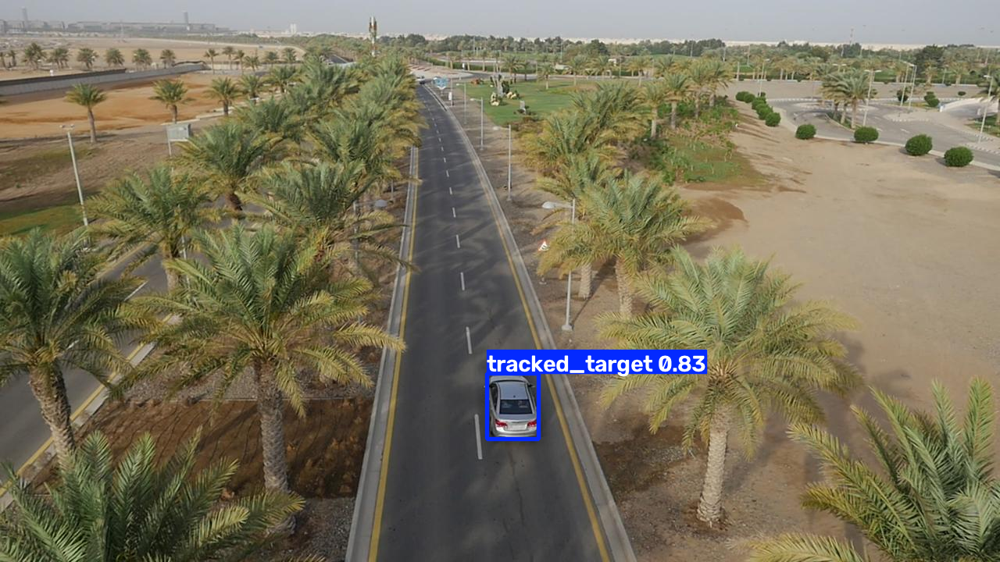

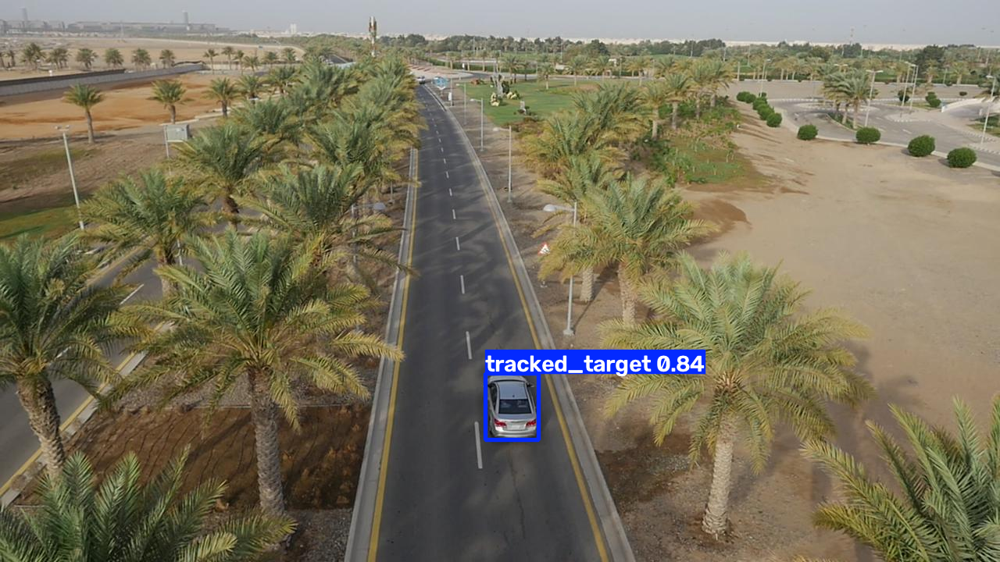

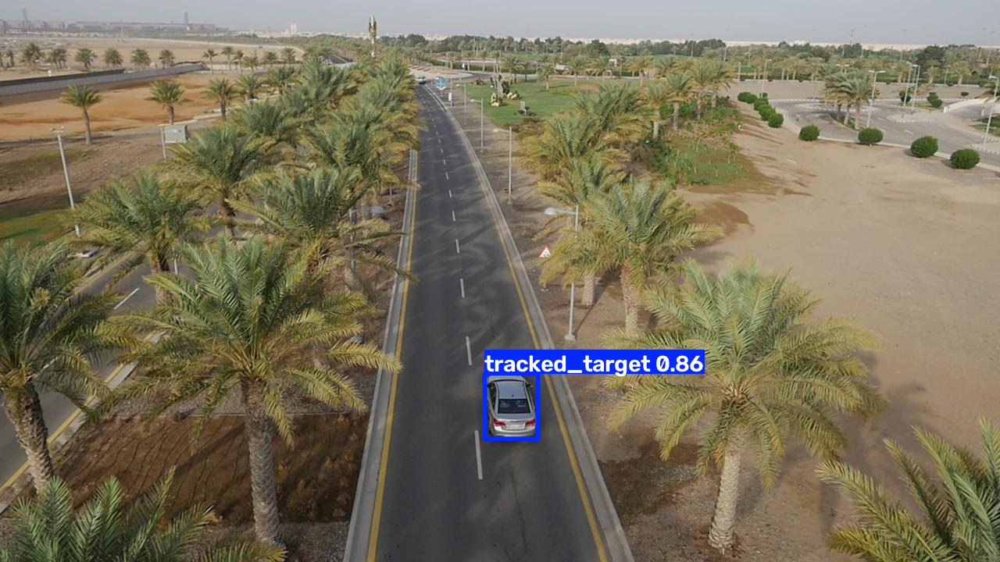

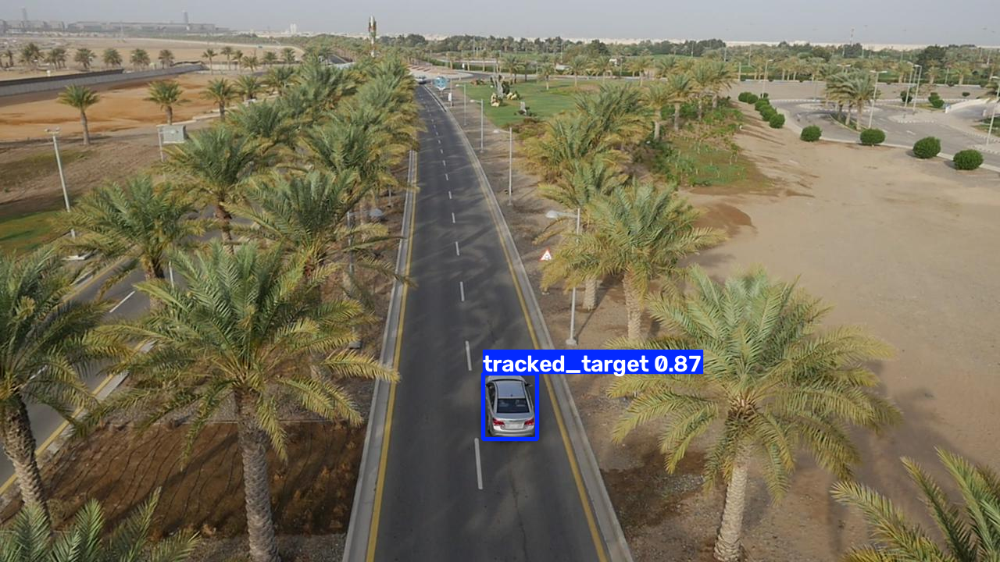

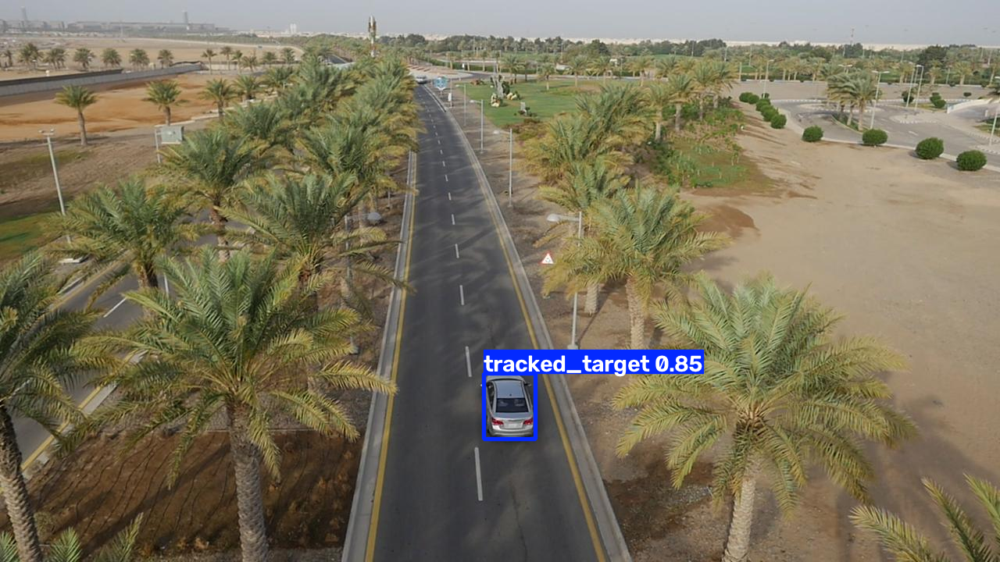

In [ ]:
from ultralytics import YOLO
from IPython.display import display
from PIL import Image

model = YOLO(
    "/content/runs/uav_target_detector/weights/best.pt"
)

# Run prediction on the car1 sequence
results = model.predict(
    source=str(frames_dir / "UAV123_10fps" / "car1"),
    conf=0.25,
    imgsz=640,
    device=0,
    save=True,
    project="/content/runs",
    name="car1_predictions"
)

# Display the first 5 predictions correctly using result.plot()
for result in results[:5]:
    # result.plot() returns a BGR numpy array, we convert it to RGB for PIL display
    annotated_img = result.plot()[:, :, ::-1]
    display(Image.fromarray(annotated_img))

In [ ]:
import shutil

save_dir = Path(
    "/content/drive/MyDrive/UAV_Project/models"
)
save_dir.mkdir(parents=True, exist_ok=True)

shutil.copy2(
    "/content/runs/uav_target_detector/weights/best.pt",
    save_dir / "uav_target_detector.pt"
)

print("Model saved:", save_dir)

Model saved: /content/drive/MyDrive/UAV_Project/models


In [ ]:
from ultralytics import YOL